In [1]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("paultimothymooney/kermany2018")

print("Path to dataset files:", path)

100%|██████████| 10.8G/10.8G [02:00<00:00, 96.3MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/paultimothymooney/kermany2018/versions/2


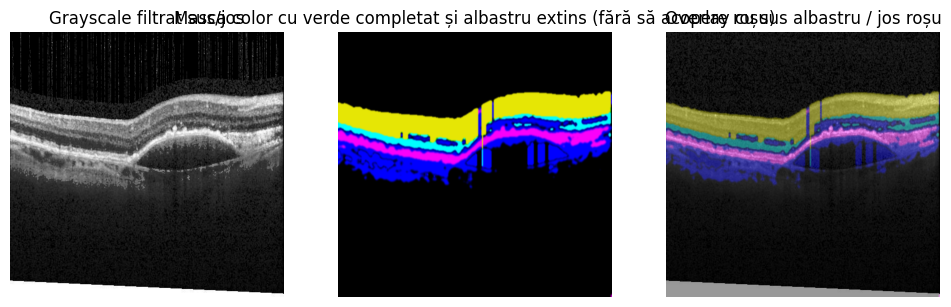

In [3]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# === Load imagine ===
img_path = "/root/.cache/kagglehub/datasets/paultimothymooney/kermany2018/versions/2/OCT2017 /test/CNV/CNV-103044-10.jpeg"
img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
if img is None:
    raise FileNotFoundError(f"Imaginea nu a fost găsită: {img_path}")

# === Contrast CLAHE doar pentru pixelii > black_thresh ===
black_thresh = 60
mask_nonblack = img > black_thresh

clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8,8))
contrast_img = img.copy()
contrast_img[mask_nonblack] = clahe.apply(img)[mask_nonblack]

H, W = img.shape
processed_img = contrast_img.copy()




# === 1️⃣ Filtrare sus/jos pe baza pixelilor negri în grayscale ===
for x in range(W):
    col = contrast_img[:, x]
    indices_nonblack = np.where(col > black_thresh)[0]
    if len(indices_nonblack) > 0:
        top = indices_nonblack.min()
        bottom = indices_nonblack.max()
        ys = np.arange(H)
        mask_filter = (ys >= top - 30) & (ys <= bottom + 50)
        processed_img[:, x] = processed_img[:, x] * mask_filter
    else:
        processed_img[:, x] = 0

# === 2️⃣ Creează masca color pe baza intensității filtrate ===
intervals = [0, 80, 110, 110,170, 256]
color_map = [
    (0, 0, 0),         # negru
    (0, 255, 0),        # verde
    (255, 0, 0),      # roșu
    (0, 0, 255),       # albastru
    (250,0,250),
]

mask_color = np.zeros((H, W, 3), dtype=np.uint8)
for i in range(len(intervals)-1):
    mask = (processed_img >= intervals[i]) & (processed_img < intervals[i+1])
    mask_color[mask] = color_map[i]



# === 2.5️⃣ Completează verde între verde dacă nu e albastru între ele (fără să acopere roșu) ===
for x in range(W):
    col = mask_color[:, x]
    green_indices = np.where(col[:,1]==255)[0]
    blue_indices  = np.where(col[:,2]==255)[0]
    red_indices   = np.where(col[:,0]==255)[0]

    if len(green_indices) > 1:
        for i in range(len(green_indices)-1):
            start = green_indices[i]
            end   = green_indices[i+1]
            # dacă între ele nu e albastru
            if not np.any(np.isin(np.arange(start+1, end), blue_indices)):
                for y in range(start+1, end):
                    if y not in red_indices:  # nu acoperim roșu
                        col[y,:] = (0, 255, 0)




    # === Extindere albastru până la margini dacă nu este legat de margine (fără să acopere roșu) ===
    col_blue_indices = np.where(col[:,2]==255)[0]
    if len(col_blue_indices) > 0:
        top_blue = col_blue_indices.min()
        bottom_blue = col_blue_indices.max()
        for y in range(0, top_blue):
            if y not in red_indices:
                col[y,:] = (80,10,10)
        for y in range(bottom_blue+1, H):
            if y not in red_indices:
                col[y,:] = (80,10,10)

    mask_color[:, x] = col



# === 3️⃣ Filtrare suplimentară sus/albastru și jos/rosu pe masca color ===
blue_mask = (mask_color[:,:,1] == 255)
red_mask  = (mask_color[:,:,1] == 255)

new_mask = mask_color.copy()

for x in range(W):
    # Sus/albastru
    col_blue = np.where(blue_mask[:, x])[0]
    if len(col_blue) > 0:
        top_blue = col_blue.min()
        ys = np.arange(H)
        mask_filter_blue = ys >= top_blue - 30
    else:
        mask_filter_blue = np.ones(H, dtype=bool)

    # Jos/rosu
    col_red = np.where(red_mask[:, x])[0]
    if len(col_red) > 0:
        bottom_red = col_red.max()
        ys = np.arange(H)
        mask_filter_red = ys <= bottom_red + 40
    else:
        mask_filter_red = np.ones(H, dtype=bool)

    # Combinare sus/jos
    final_mask = mask_filter_blue & mask_filter_red
    new_mask[:, x] = new_mask[:, x] * final_mask[:, None]

# === 4️⃣ Transformăm pixelii rămași negri în verde (fără să atingem roșu sau albastru) ===
black_pixels = (new_mask[:,:,0]==0) & (new_mask[:,:,1]==0) & (new_mask[:,:,2]==0)
new_mask[black_pixels] = (0, 225, 0)




green_pixels = (new_mask[:,:,0] == 0) & (new_mask[:,:,1] >= 200) & (new_mask[:,:,2] == 0)
new_mask[green_pixels] = (0,0,0)

brown_pixels = (new_mask[:,:,0] == 80) & (new_mask[:,:,1] == 10) & (new_mask[:,:,2] == 10)
new_mask[brown_pixels] = (0,0,0)

















# ==== Kernel pentru extindere ====
kernel_size = 3   # ajustează după nevoie: 5 -> 2 pixeli, 7 -> 3 pixeli etc.
kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (kernel_size, kernel_size))

# ==== Roz ====
pink_mask = (new_mask[:,:,0] > 200) & (new_mask[:,:,1] < 80) & (new_mask[:,:,2] > 200)
pink_uint8 = pink_mask.astype(np.uint8) * 255

pink_dilated = cv2.dilate(pink_uint8, kernel)
new_pink_zone = (pink_dilated == 255) & (~pink_mask)  # doar extindere

# NU suprascriem albastru
blue_mask = (new_mask[:,:,0] < 50) & (new_mask[:,:,1] < 50) & (new_mask[:,:,2] > 200)
new_pink_zone[blue_mask] = False

# aplicăm roz
new_mask[new_pink_zone] = (255, 0, 255)

# ==== Albastru ====
blue_mask = (new_mask[:,:,0] < 50) & (new_mask[:,:,1] < 50) & (new_mask[:,:,2] > 200)
blue_uint8 = blue_mask.astype(np.uint8) * 255

blue_dilated = cv2.dilate(blue_uint8, kernel)
new_blue_zone = (blue_dilated == 255) & (~blue_mask)  # doar extindere

# NU suprascriem roz
pink_mask = (new_mask[:,:,0] > 200) & (new_mask[:,:,1] < 80) & (new_mask[:,:,2] > 200)
new_blue_zone[pink_mask] = False

# aplicăm albastru
new_mask[new_blue_zone] = (0, 0, 255)







smoothed = cv2.medianBlur(new_mask, 5)   # netezire contururi dure
smoothed = cv2.GaussianBlur(smoothed, (3,5), 0)  # înmuiere fină

new_mask = smoothed












# Detectăm albastru și negru
blue_mask = (new_mask[:,:,0] < 50) & (new_mask[:,:,1] < 50) & (new_mask[:,:,2] > 200)
black_mask = (new_mask[:,:,0] == 0) & (new_mask[:,:,1] == 0) & (new_mask[:,:,2] == 0)

for x in range(W):
    col_blue = np.where(blue_mask[:, x])[0]  # pozițiile albastre din coloană
    if len(col_blue) >= 2:
        top = col_blue.min()
        bottom = col_blue.max()
        # completăm negrul dintre primul și ultimul albastru
        for y in range(top+1, bottom):
            if black_mask[y, x]:
                new_mask[y, x] = (0, 255, 255)  # devine albastru















target_color = np.array([0, 255, 255])  # culoarea de referință
new_color = np.array([230, 230, 5])      # galben

H, W, _ = new_mask.shape
result_mask = new_mask.copy()

for x in range(W):
    # găsim rândul cel mai sus unde apare culoarea target
    rows = np.where(np.all(np.abs(result_mask[:, x] - target_color) <= 10, axis=1))[0]
    if len(rows) == 0:
        continue  # dacă nu există, trecem la următoarea coloană
    top_row = rows.min()  # cel mai sus rând

    # transformăm toți pixelii colorați deasupra în galben
    for y in range(top_row):
        if not np.all(result_mask[y, x] == [0,0,0]):  # nu atingem negrul
            result_mask[y, x] = new_color

new_mask = result_mask












target_pink = np.array([255, 0, 255])   # roz
target_cyan = np.array([0, 255, 255])   # cyan / turcoaz
target_blue = np.array([0, 0, 255])     # albastru
tol = 10  # toleranță pentru culoare

H, W, _ = new_mask.shape
result_mask = new_mask.copy()

for x in range(W):
    # găsim cel mai jos rând cu roz
    pink_rows = np.where(np.all(np.abs(result_mask[:, x] - target_pink) <= tol, axis=1))[0]
    if len(pink_rows) == 0:
        continue
    bottom_pink = pink_rows.max()

    # transformăm pixelii cyan sub acest rând în albastru
    for y in range(bottom_pink+1, H):
        if np.all(np.abs(result_mask[y, x] - target_cyan) <= tol):
            result_mask[y, x] = target_blue

new_mask = result_mask














smoothed = cv2.medianBlur(new_mask, 5)   # netezire contururi dure
smoothed = cv2.GaussianBlur(smoothed, (3,5), 0)  # înmuiere fină

new_mask = smoothed















# === 4️⃣ Overlay peste imaginea originală ===
orig_rgb = cv2.cvtColor(img, cv2.COLOR_GRAY2RGB)
overlay = cv2.addWeighted(orig_rgb, 0.6, new_mask, 0.4, 0)

# === Afișare ===
plt.figure(figsize=(12,4))

plt.subplot(1,3,1)
plt.title("Grayscale filtrat sus/jos")
plt.imshow(processed_img, cmap="gray")
plt.axis("off")

plt.subplot(1,3,2)
plt.title("Masca color cu verde completat și albastru extins (fără să acopere roșu)")
plt.imshow(new_mask)
plt.axis("off")

plt.subplot(1,3,3)
plt.title("Overlay cu sus albastru / jos roșu")
plt.imshow(overlay)
plt.axis("off")

plt.show()


In [4]:
import cv2
import numpy as np

def process_oct_image(img_path):
    """
    Procesează o imagine OCT conform pașilor tăi și returnează:
    - processed_img: grayscale filtrat sus/jos
    - new_mask: masca color completată
    - overlay: overlay peste imaginea originală
    """
    # === Load imagine ===
    img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
    if img is None:
        raise FileNotFoundError(f"Imaginea nu a fost găsită: {img_path}")
    H, W = img.shape

    # === Contrast CLAHE doar pentru pixelii > black_thresh ===
    black_thresh = 60
    mask_nonblack = img > black_thresh
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8,8))
    contrast_img = img.copy()
    contrast_img[mask_nonblack] = clahe.apply(img)[mask_nonblack]
    processed_img = contrast_img.copy()

    # === 1️⃣ Filtrare sus/jos ===
    for x in range(W):
        col = contrast_img[:, x]
        indices_nonblack = np.where(col > black_thresh)[0]
        if len(indices_nonblack) > 0:
            top = indices_nonblack.min()
            bottom = indices_nonblack.max()
            ys = np.arange(H)
            mask_filter = (ys >= top - 30) & (ys <= bottom + 50)
            processed_img[:, x] = processed_img[:, x] * mask_filter
        else:
            processed_img[:, x] = 0

    # === 2️⃣ Creează masca color ===
    intervals = [0, 80, 110, 110,170, 256]
    color_map = [
        (0, 0, 0),         # negru
        (0, 255, 0),       # verde
        (255, 0, 0),       # roșu
        (0, 0, 255),       # albastru
        (250,0,250),       # roz
    ]
    mask_color = np.zeros((H, W, 3), dtype=np.uint8)
    for i in range(len(intervals)-1):
        mask = (processed_img >= intervals[i]) & (processed_img < intervals[i+1])
        mask_color[mask] = color_map[i]

    # === 2.5️⃣ Completează verde și extindere albastru ===
    kernel_size = 3
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (kernel_size, kernel_size))
    for x in range(W):
        col = mask_color[:, x]
        green_indices = np.where(col[:,1]==255)[0]
        blue_indices  = np.where(col[:,2]==255)[0]
        red_indices   = np.where(col[:,0]==255)[0]

        if len(green_indices) > 1:
            for i in range(len(green_indices)-1):
                start = green_indices[i]
                end   = green_indices[i+1]
                if not np.any(np.isin(np.arange(start+1, end), blue_indices)):
                    for y in range(start+1, end):
                        if y not in red_indices:
                            col[y,:] = (0, 255, 0)

        col_blue_indices = np.where(col[:,2]==255)[0]
        if len(col_blue_indices) > 0:
            top_blue = col_blue_indices.min()
            bottom_blue = col_blue_indices.max()
            for y in range(0, top_blue):
                if y not in red_indices:
                    col[y,:] = (80,10,10)
            for y in range(bottom_blue+1, H):
                if y not in red_indices:
                    col[y,:] = (80,10,10)
        mask_color[:, x] = col

    # === 3️⃣ Filtrare suplimentară sus/albastru și jos/rosu ===
    blue_mask = (mask_color[:,:,1] == 255)
    red_mask  = (mask_color[:,:,1] == 255)
    new_mask = mask_color.copy()
    for x in range(W):
        col_blue = np.where(blue_mask[:, x])[0]
        if len(col_blue) > 0:
            top_blue = col_blue.min()
            ys = np.arange(H)
            mask_filter_blue = ys >= top_blue - 30
        else:
            mask_filter_blue = np.ones(H, dtype=bool)
        col_red = np.where(red_mask[:, x])[0]
        if len(col_red) > 0:
            bottom_red = col_red.max()
            ys = np.arange(H)
            mask_filter_red = ys <= bottom_red + 40
        else:
            mask_filter_red = np.ones(H, dtype=bool)
        final_mask = mask_filter_blue & mask_filter_red
        new_mask[:, x] = new_mask[:, x] * final_mask[:, None]

    # === 4️⃣ Transformăm pixelii rămași negri în verde ===
    black_pixels = (new_mask[:,:,0]==0) & (new_mask[:,:,1]==0) & (new_mask[:,:,2]==0)
    new_mask[black_pixels] = (0, 225, 0)

    green_pixels = (new_mask[:,:,0] == 0) & (new_mask[:,:,1] >= 200) & (new_mask[:,:,2] == 0)
    new_mask[green_pixels] = (0,0,0)
    brown_pixels = (new_mask[:,:,0] == 80) & (new_mask[:,:,1] == 10) & (new_mask[:,:,2] == 10)
    new_mask[brown_pixels] = (0,0,0)

    # ==== Roz și Albastru ====
    pink_mask = (new_mask[:,:,0] > 200) & (new_mask[:,:,1] < 80) & (new_mask[:,:,2] > 200)
    pink_uint8 = pink_mask.astype(np.uint8) * 255
    pink_dilated = cv2.dilate(pink_uint8, kernel)
    new_pink_zone = (pink_dilated == 255) & (~pink_mask)
    blue_mask = (new_mask[:,:,0] < 50) & (new_mask[:,:,1] < 50) & (new_mask[:,:,2] > 200)
    new_pink_zone[blue_mask] = False
    new_mask[new_pink_zone] = (255, 0, 255)

    blue_uint8 = blue_mask.astype(np.uint8) * 255
    blue_dilated = cv2.dilate(blue_uint8, kernel)
    new_blue_zone = (blue_dilated == 255) & (~blue_mask)
    pink_mask = (new_mask[:,:,0] > 200) & (new_mask[:,:,1] < 80) & (new_mask[:,:,2] > 200)
    new_blue_zone[pink_mask] = False
    new_mask[new_blue_zone] = (0, 0, 255)

    # ==== Netezire ====
    smoothed = cv2.medianBlur(new_mask, 5)
    smoothed = cv2.GaussianBlur(smoothed, (3,5), 0)
    new_mask = smoothed

    # ==== Detectăm albastru și negru pentru completare ====
    blue_mask = (new_mask[:,:,0] < 50) & (new_mask[:,:,1] < 50) & (new_mask[:,:,2] > 200)
    black_mask = (new_mask[:,:,0] == 0) & (new_mask[:,:,1] == 0) & (new_mask[:,:,2] == 0)
    for x in range(W):
        col_blue = np.where(blue_mask[:, x])[0]
        if len(col_blue) >= 2:
            top = col_blue.min()
            bottom = col_blue.max()
            for y in range(top+1, bottom):
                if black_mask[y, x]:
                    new_mask[y, x] = (0, 255, 255)

    # ==== Galben deasupra cyan ====
    target_color = np.array([0, 255, 255])
    new_color = np.array([230, 230, 5])
    result_mask = new_mask.copy()
    for x in range(W):
        rows = np.where(np.all(np.abs(result_mask[:, x] - target_color) <= 10, axis=1))[0]
        if len(rows) == 0:
            continue
        top_row = rows.min()
        for y in range(top_row):
            if not np.all(result_mask[y, x] == [0,0,0]):
                result_mask[y, x] = new_color
    new_mask = result_mask

    # ==== Cyan sub roz devine albastru ====
    target_pink = np.array([255, 0, 255])
    target_cyan = np.array([0, 255, 255])
    target_blue = np.array([0, 0, 255])
    tol = 10
    result_mask = new_mask.copy()
    for x in range(W):
        pink_rows = np.where(np.all(np.abs(result_mask[:, x] - target_pink) <= tol, axis=1))[0]
        if len(pink_rows) == 0:
            continue
        bottom_pink = pink_rows.max()
        for y in range(bottom_pink+1, H):
            if np.all(np.abs(result_mask[y, x] - target_cyan) <= tol):
                result_mask[y, x] = target_blue
    new_mask = result_mask

    # ==== Final overlay ====
    orig_rgb = cv2.cvtColor(img, cv2.COLOR_GRAY2RGB)
    overlay = cv2.addWeighted(orig_rgb, 0.6, new_mask, 0.4, 0)

    return processed_img, new_mask, overlay



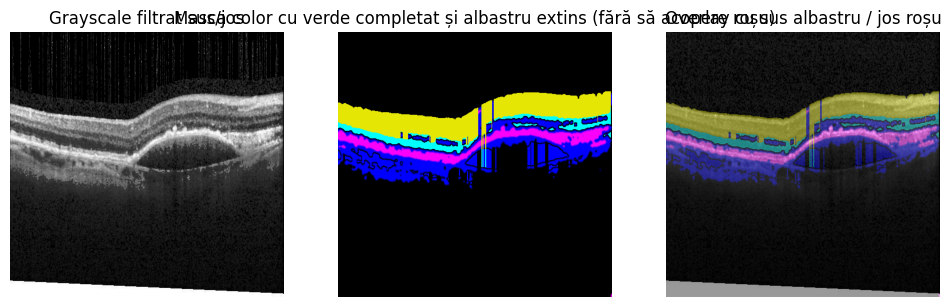

In [8]:
import matplotlib.pyplot as plt

# Path-ul imaginii
img_path = "/root/.cache/kagglehub/datasets/paultimothymooney/kermany2018/versions/2/OCT2017 /test/CNV/CNV-103044-10.jpeg"

# Apelăm funcția
processed_img, mask_color, overlay = process_oct_image(img_path)

# Afișăm rezultatele
plt.figure(figsize=(12,4))

plt.subplot(1,3,1)
plt.title("Grayscale filtrat sus/jos")
plt.imshow(processed_img, cmap="gray")
plt.axis("off")

plt.subplot(1,3,2)
plt.title("Masca color cu verde completat și albastru extins (fără să acopere roșu)")
plt.imshow(mask_color)
plt.axis("off")

plt.subplot(1,3,3)
plt.title("Overlay cu sus albastru / jos roșu")
plt.imshow(overlay)
plt.axis("off")

plt.show()


In [10]:
import os
from tqdm import tqdm
import cv2

train_folder = "/root/.cache/kagglehub/datasets/paultimothymooney/kermany2018/versions/2/OCT2017 /train"
output_folder = "/root/.cache/kagglehub/masks_train2"

categories = ["CNV", "DRUSEN", "NORMAL"]

os.makedirs(output_folder, exist_ok=True)

for category in categories:
    cat_folder = os.path.join(train_folder, category)
    out_cat_folder = os.path.join(output_folder, category)
    os.makedirs(out_cat_folder, exist_ok=True)

    # Luăm primele 2000 de imagini
    img_files = sorted(os.listdir(cat_folder))[:2000]

    for img_file in tqdm(img_files, desc=f"Processing {category}"):
        img_path = os.path.join(cat_folder, img_file)
        try:
            # Procesăm imaginea
            _, mask_color, _ = process_oct_image(img_path)

            # Salvăm doar masca color
            base_name = os.path.splitext(img_file)[0]
            cv2.imwrite(os.path.join(out_cat_folder, f"{base_name}_mask.png"), mask_color)
        except Exception as e:
            print(f"Error processing {img_path}: {e}")


Processing NORMAL: 100%|██████████| 2000/2000 [2:07:41<00:00,  3.83s/it]


In [12]:
!du -sh "/root/.cache/kagglehub/masks_train2"


277M	/root/.cache/kagglehub/masks_train2


In [13]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [14]:
import os
os.makedirs("/content/drive/MyDrive/masks2", exist_ok=True)


In [15]:
!cp -r "/root/.cache/kagglehub/masks_train2" "/content/drive/MyDrive/masks2/"
